# 5 · Education


Presenter: Huang Yixuan

Original data file `team_master.csv` is now read from `Education_Data.csv` with identical values.

Data: `Education_Data.csv` (this member's columns of the group dataset).

In [1]:
from pathlib import Path
import os
import pandas as pd

# Locate this member's folder (the folder that contains Education_Data.csv).
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'Education_Data.csv').is_file())
COMBINED = pd.read_csv(ROOT / 'Education_Data.csv', float_precision='round_trip')

# Each section reads its own columns from the one combined dataset, under the column names its code expects.
SECTIONS = {
    'healthcare': dict(years=(2010, 2025), integer=['year', 'resident_live_births_number'], columns={
        'Year': 'year', 'TFR': 'tfr_per_female',
        'resident_live_births_number': 'resident_live_births_number',
        'cpi_health_2024_100': 'cpi_health_2024_100',
        'cpi_medicines_health_products_2024_100': 'cpi_medicines_health_products_2024_100',
        'cpi_outpatient_care_2024_100': 'cpi_outpatient_care_2024_100',
        'cpi_inpatient_care_2024_100': 'cpi_inpatient_care_2024_100',
        'cpi_other_health_services_2024_100': 'cpi_other_health_services_2024_100',
        'cpi_health_insurance_2024_100': 'cpi_health_insurance_2024_100',
        'cpi_polyclinic_fees_2024_100': 'cpi_polyclinic_fees_2024_100',
        'cpi_gp_fees_2024_100': 'cpi_gp_fees_2024_100',
        'cpi_specialist_outpatient_fees_2024_100': 'cpi_specialist_outpatient_fees_2024_100',
        'gov_health_development_sgd_million': 'gov_health_development_sgd_million',
        'gov_health_operating_sgd_million': 'gov_health_operating_sgd_million',
        'doctors_per_10000_total_population': 'doctors_per_10000_total_population',
        'nurses_per_10000_total_population': 'nurses_per_10000_total_population',
        'acute_hospital_beds_total_number': 'acute_hospital_beds_total_number',
        'acute_hospital_beds_public_number': 'acute_hospital_beds_public_number',
        'acute_hospital_beds_nonprofit_number': 'acute_hospital_beds_nonprofit_number',
        'acute_hospital_beds_private_number': 'acute_hospital_beds_private_number',
        'acute_hospitals_public_number': 'acute_hospitals_public_number',
        'acute_hospitals_private_number': 'acute_hospitals_private_number',
        'public_polyclinics_number': 'public_polyclinics_number',
        'young_children_health_inflation_2019base_pct': 'young_children_health_inflation_2019base_pct',
        'general_households_health_inflation_2019base_pct': 'general_households_health_inflation_2019base_pct',
        'Gov_Health_per_Capita': 'gov_health_per_capita_sgd',
        'Gov_Health_Total': 'gov_health_expenditure_sgd_million',
        'Gov_Health_%_GDP': 'gov_health_expenditure_gdp_pct',
        'HES_Health_Monthly': 'hes_all_households_health_monthly_sgd',
        'HES_Health_Share_%': 'hes_all_households_health_share_pct'},
        order=['year',
               'tfr_per_female',
               'resident_live_births_number',
               'cpi_health_2024_100',
               'cpi_medicines_health_products_2024_100',
               'cpi_outpatient_care_2024_100',
               'cpi_inpatient_care_2024_100',
               'cpi_other_health_services_2024_100',
               'cpi_health_insurance_2024_100',
               'cpi_polyclinic_fees_2024_100',
               'cpi_gp_fees_2024_100',
               'cpi_specialist_outpatient_fees_2024_100',
               'gov_health_per_capita_sgd',
               'gov_health_expenditure_sgd_million',
               'gov_health_expenditure_gdp_pct',
               'gov_health_development_sgd_million',
               'gov_health_operating_sgd_million',
               'doctors_per_10000_total_population',
               'nurses_per_10000_total_population',
               'hes_all_households_health_monthly_sgd',
               'hes_all_households_health_share_pct',
               'acute_hospital_beds_total_number',
               'acute_hospital_beds_public_number',
               'acute_hospital_beds_nonprofit_number',
               'acute_hospital_beds_private_number',
               'acute_hospitals_public_number',
               'acute_hospitals_private_number',
               'public_polyclinics_number',
               'young_children_health_inflation_2019base_pct',
               'general_households_health_inflation_2019base_pct']),
    'housing_hdb_quarterly': dict(years=(2000, 2025), integer=['Year'], columns={
        'Year': 'Year', 'HDB_Resale_Index_Q4': '4', 'HDB_Resale_Index_Q3': '3',
        'HDB_Resale_Index_Q2': '2', 'HDB_Resale_Index_Q1': '1'}),
    'housing_fertility': dict(years=(2000, 2025), integer=['Year'], columns={
        'Year': 'Year', 'TFR': 'Total_Fertility_Rate',
        **{f'ASFR_{a}_{a + 4}': f'{a} - {a + 4} Years' for a in range(15, 50, 5)}}),
    'housing_private': dict(years=(2000, 2025), integer=['Year'], columns={
        'Year': 'Year', 'Private_Landed_Index_URA': 'Private_Landed_Index',
        'Private_Non_Landed_Index_URA': 'Private_Non_Landed_Index'}),
    'marriage': dict(years=(2000, 2025), integer=['Year'], columns={c: c for c in [
        'Year', 'TFR', 'F_Marriage_Rate_20_24', 'F_Marriage_Rate_25_29', 'F_Marriage_Rate_30_34',
        'F_Marriage_Rate_35_39', 'F_Marriage_Rate_40_44', 'Median_Age_First_Birth', 'Brides_25_29', 'Brides_30_34']}),
    'income': dict(years=(2010, 2025), integer=['Year'], columns={c: c for c in ['Year', 'TFR', 'PM_Avg', 'PM_Median', 'CPI_All_Items_2024_100', 'CPI_All_Items_2010_100', 'PM_Avg_Real_2010', 'PM_Median_Real_2010', 'Real_Growth_%', 'Real_Growth_D1', 'Real_Growth_D2', 'Real_Growth_D3', 'Real_Growth_D4', 'Real_Growth_D5', 'Real_Growth_D6', 'Real_Growth_D7', 'Real_Growth_D8', 'Real_Growth_D9', 'Gini_Before_Transfers', 'Gini_After_Transfers', 'Real_Growth_D1_M810361', 'Real_Growth_D10_M810361']}),
    'education': dict(years=(2000, 2025), integer=['Year'],
                      columns={c: c for c in ['Year', 'TFR', 'ASFR_15_19', 'ASFR_20_24', 'ASFR_25_29', 'ASFR_30_34', 'ASFR_35_39', 'ASFR_40_44', 'Gini_Before_Transfers', 'Gini_After_Transfers', 'Income_Decile_1', 'Income_Decile_2', 'Income_Decile_3', 'Income_Decile_4', 'Income_Decile_5', 'Income_Decile_6', 'Income_Decile_7', 'Income_Decile_8', 'Income_Decile_9', 'F_Marriage_Rate_20_24', 'F_Marriage_Rate_25_29', 'F_Marriage_Rate_30_34', 'F_Marriage_Rate_35_39', 'F_Marriage_Rate_40_44', 'Median_Age_First_Birth', 'Brides_25_29', 'Brides_30_34', 'PM_Avg', 'PM_Median', 'Real_Growth_%', 'CPI_All_Items_2024_100', 'CPI_All_Items_2010_100', 'PM_Avg_Real_2010', 'PM_Median_Real_2010', 'Real_Growth_D1', 'Real_Growth_D2', 'Real_Growth_D3', 'Real_Growth_D4', 'Real_Growth_D5', 'Real_Growth_D6', 'Real_Growth_D7', 'Real_Growth_D8', 'Real_Growth_D9', 'Real_Growth_D1_M810361', 'Real_Growth_D10_M810361', 'HH_Size_Employed', 'HDB_Resale_Price_Index', 'Private_Landed_Index', 'Private_Non_Landed_Index', 'HDB_YoY_%', 'Landed_YoY_%', 'NonLanded_YoY_%', 'Edu_CPI', 'Edu_CPI_General', 'Edu_CPI_Tuition', 'Edu_CPI_Textbooks', 'Edu_Public_Total', 'Edu_Primary_per_Student', 'Edu_Secondary_per_Student', 'Edu_Op_Primary', 'Edu_Op_Secondary_JC', 'Edu_Op_Tertiary', 'Edu_Op_Other', 'Edu_Op_ITE', 'Edu_Development', 'Univ_Women_25_34_%', 'Univ_Women_35_44_%', 'Childcare_Places', 'Preschool_Age6_%', 'Pupils_per_Teacher', 'Health_CPI', 'Health_CPI_Medicines', 'Health_CPI_Outpatient', 'Health_CPI_Inpatient', 'Health_CPI_Other', 'Health_CPI_Insurance', 'HES_Health_Monthly', 'HES_Health_Share_%', 'Gov_Health_Total', 'Gov_Health_per_Capita', 'Gov_Health_%_GDP']}),
}


def load_section(name):
    spec = SECTIONS[name]
    y0, y1 = spec['years']
    frame = COMBINED.loc[COMBINED.Year.between(y0, y1), list(spec['columns'])]
    frame = frame.rename(columns=spec['columns']).reset_index(drop=True)
    if spec.get('order'):
        frame = frame[spec['order']]
    for column in spec['integer']:
        frame[column] = frame[column].astype('int64')
    return frame


print(f'Education_Data.csv: {COMBINED.shape[0]} years × {COMBINED.shape[1]} columns')

Education_Data.csv: 26 years × 81 columns


In [2]:
# Education helper code and saved figures are in sections/education.
os.chdir(ROOT / 'sections' / 'education')

## Education and fertility

These five education figures match the updated group presentation. The final comparison includes Pearson r and two-sided p-values for 16 annual observations, 2010–2025.

The first four plotting blocks and original helper files are preserved. The displayed images match the presentation.


In [3]:
from pathlib import Path
import base64
import importlib.util
import json
import logging
import sys

import numpy as np
import plotly.io as pio
from IPython.display import Image, display

BASE = Path.cwd()
if not (BASE / "source/dashboard_v6/core.py").is_file():
    raise FileNotFoundError("Keep the sections/education folder next to this notebook.")

logging.getLogger("streamlit").setLevel(logging.ERROR)
spec = importlib.util.spec_from_file_location("core", BASE / "source/dashboard_v6/core.py")
core = importlib.util.module_from_spec(spec)
sys.modules["core"] = core
spec.loader.exec_module(core)

# Combined notebook: the dashboard helpers read the education columns from Fertility_Combined_Data.csv.
core.master = lambda: load_section("education")
core.dictionary = lambda: pd.DataFrame(columns=["label", "source_table"], index=pd.Index([], name="column"))

# Replace Streamlit's page controls with fixed notebook selections.
# The plotting statements and original helper functions are unchanged.
class NotebookContext:
    def __enter__(self):
        return self
    def __exit__(self, *args):
        return False

core.st.columns = lambda n: [NotebookContext() for _ in range(n if isinstance(n, int) else len(n))]
core.st.selectbox = lambda label, options, **kw: options[0]
core.st.segmented_control = lambda *args, **kw: kw.get("default")
core.st.select_slider = lambda label, options, **kw: kw.get("value", options[-1])
core.card = lambda *args: NotebookContext()
for name in ["header", "kpis", "note", "kpi"]:
    setattr(core, name, lambda *args, **kw: None)
for name in ["markdown", "caption"]:
    setattr(core.st, name, lambda *args, **kw: None)

chart_names = ["01_prices", "02_inflation", "03_per_student", "04_funding_2025", "05_tfr"]
figures = {}

def normalise(value):
    if isinstance(value, dict):
        if "bdata" in value and "dtype" in value:
            array = np.frombuffer(base64.b64decode(value["bdata"]), dtype=value["dtype"])
            if value.get("shape"):
                array = array.reshape(tuple(int(n) for n in str(value["shape"]).split(",")))
            return array.tolist()
        return {key: normalise(item) for key, item in value.items()}
    if isinstance(value, (list, tuple)):
        return [normalise(item) for item in value]
    if isinstance(value, np.ndarray):
        return value.tolist()
    if isinstance(value, np.generic):
        return value.item()
    return value

def show_in_notebook(figure, *args, **kwargs):
    first_trace = figure.data[0].type
    if first_trace == "heatmap":
        name = "02_inflation"
    elif first_trace == "bar":
        name = "03_per_student"
    elif first_trace == "treemap":
        name = "04_funding_2025"
    elif len(figure.data) == 4:
        name = "01_prices"
    else:
        name = "05_tfr"
    reference = pio.read_json(BASE / "figures" / f"{name}.json")
    # Retain the exact saved PPT layout, including its existing annotations.
    figure.layout = reference.layout
    actual = normalise(json.loads(figure.to_json())["data"])
    expected = normalise(json.loads(reference.to_json())["data"])
    if actual != expected:
        raise AssertionError(f"The chart traces differ from the PPT reference: {name}")
    figures[name] = figure
    # Display the very same PNG used in the PPT, with no re-rendering.
    width = 750 if name == "04_funding_2025" else 1000
    display(Image(filename=str(BASE / "figures" / f"{name}.png"), width=width))

core.show = show_in_notebook


2026-10-19 12:50:47.637 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager


2026-10-19 12:50:47.639 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager


2026-10-19 12:50:47.641 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager


In [4]:
import numpy as np
import plotly.graph_objects as go
import streamlit as st

from core import (AQUA, ORANGE, SERIES, VIOLET, card, data, header, index_lines, kpi, kpis, link, note, short, show, src,
                  style, trend)

df = data()
e = df.dropna(subset=["Edu_CPI"])
header("Education", "What families pay for education, and what the government spends")
kpis([
    kpi(df, "Edu_CPI_Tuition", "{:.0f}", title="Tuition prices"),
    kpi(df, "Edu_CPI_General", "{:.0f}", title="General education prices"),
    kpi(df, "Edu_Primary_per_Student", prefix="S$", title="Gov spend / primary pupil"),
    kpi(df, "Edu_Secondary_per_Student", prefix="S$", title="Gov spend / secondary pupil"),
    kpi(df, "Edu_Public_Total", prefix="S$", suffix="m", title="Gov education spending"),
])

CPI = {"Edu_CPI_Tuition": ORANGE, "Edu_CPI_General": AQUA, "Edu_CPI_Textbooks": VIOLET}


2026-10-19 12:50:47.653 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


2026-10-19 12:50:47.655 WARNING streamlit.runtime.state.session_state_proxy: Session state does not function when running a script without `streamlit run`


## 1. Education prices and TFR

Source: SingStat M213801 and M810091.

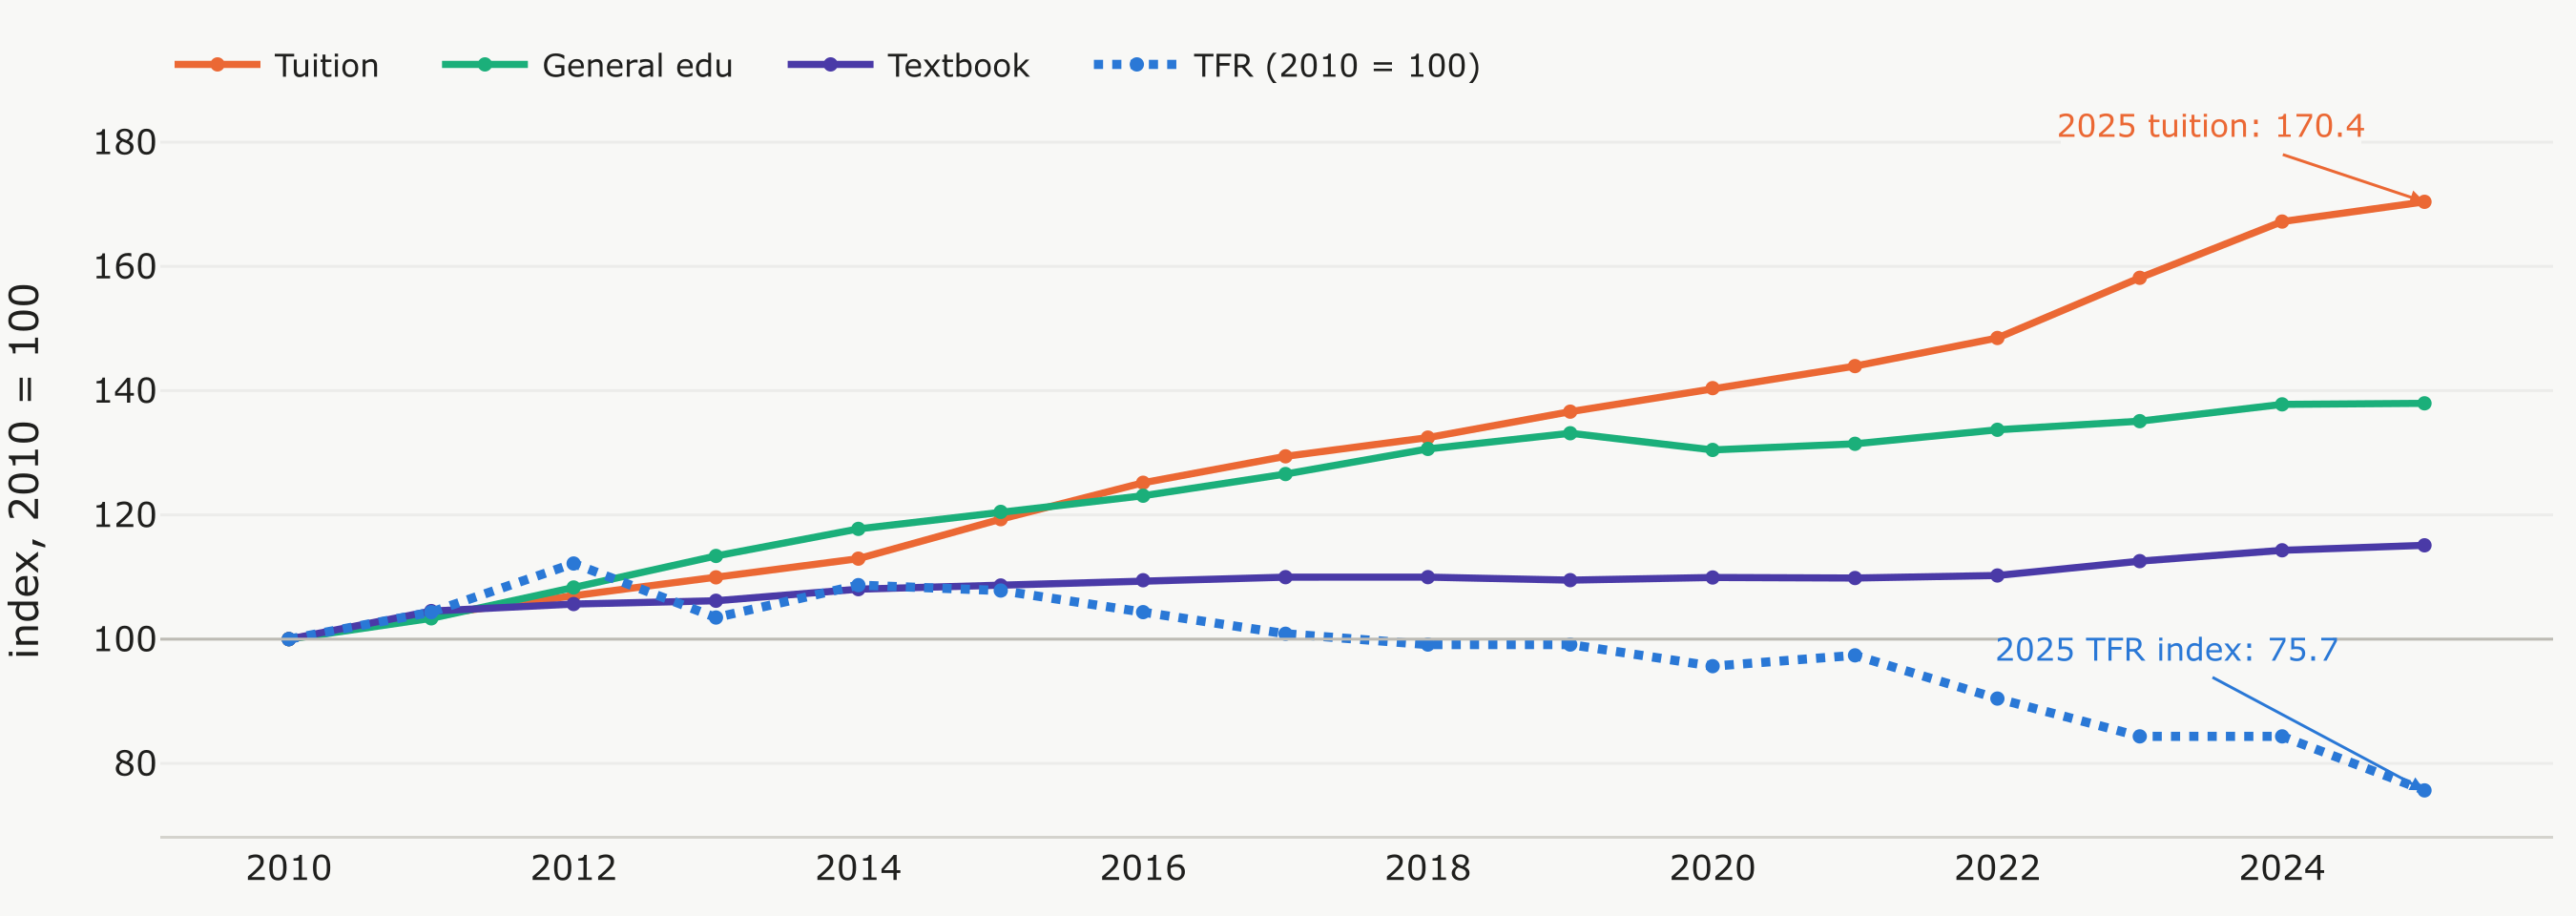

In [5]:
c1, c2 = st.columns(2)
with c1, card("Education prices"):
    show(index_lines(df, list(CPI), CPI, {c: short(c).replace(" prices", "") for c in CPI}, h=320))
    note("Tuition: " + trend(df, "Edu_CPI_Tuition", "{:.0f}"), "2010 = 100", src("Edu_CPI", "TFR"))



**Insight:** Tuition prices rose 70.4%, while TFR fell 24.3% from 2010 to 2025. Higher education costs may add to the expected cost of raising a child.

## 2. Education price changes

Source: SingStat M213801. Policy context: SingStat CPI paper and IRAS GST guidance.

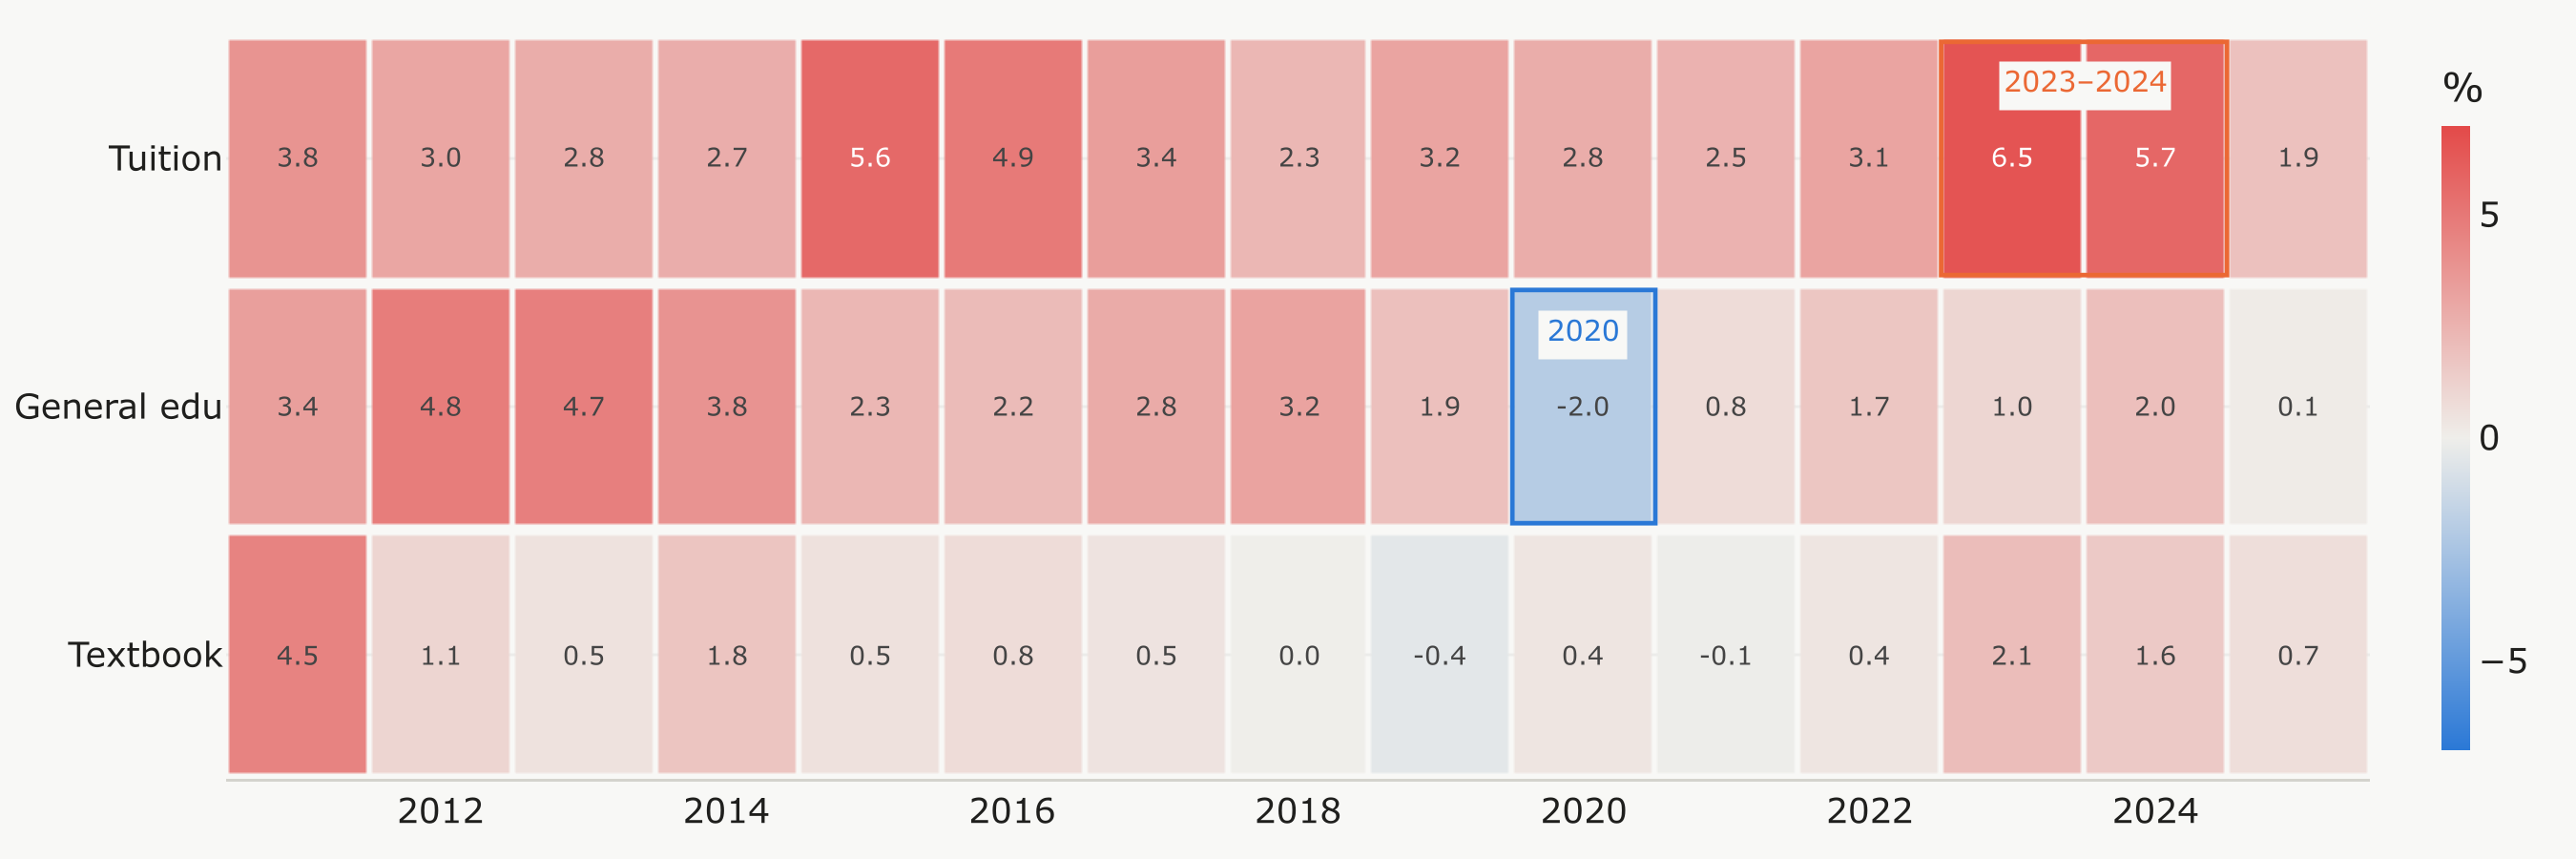

In [6]:
with c2, card("When prices rose or fell"):
    z = e.set_index("Year")[list(CPI)].pct_change().mul(100).dropna(how="all").T
    fig = go.Figure(go.Heatmap(z=z.values, x=z.columns, y=[short(c).replace(" prices", "") for c in CPI],
                               colorscale=[[0, "#2a78d6"], [0.5, "#efeeea"], [1, "#e34948"]], zmin=-7, zmax=7, xgap=2, ygap=4,
                               text=np.round(z.values, 1), texttemplate="%{text:.1f}", textfont=dict(size=9),
                               colorbar=dict(title="%", thickness=10), hovertemplate="%{y}, %{x}: %{z:+.1f}%<extra></extra>"))
    fig.update_yaxes(autorange="reversed")
    show(style(fig, 320, legend=False, hover="closest"))
    note("annual % change in each price index", src("Edu_CPI"))



**Insight:** General education prices fell 2.0% in 2020, alongside enhanced preschool subsidies. Tuition prices rose sharply in 2023–2024.

## 3. Government spending per student

Source: SingStat M850291. Nominal S$, financial years.

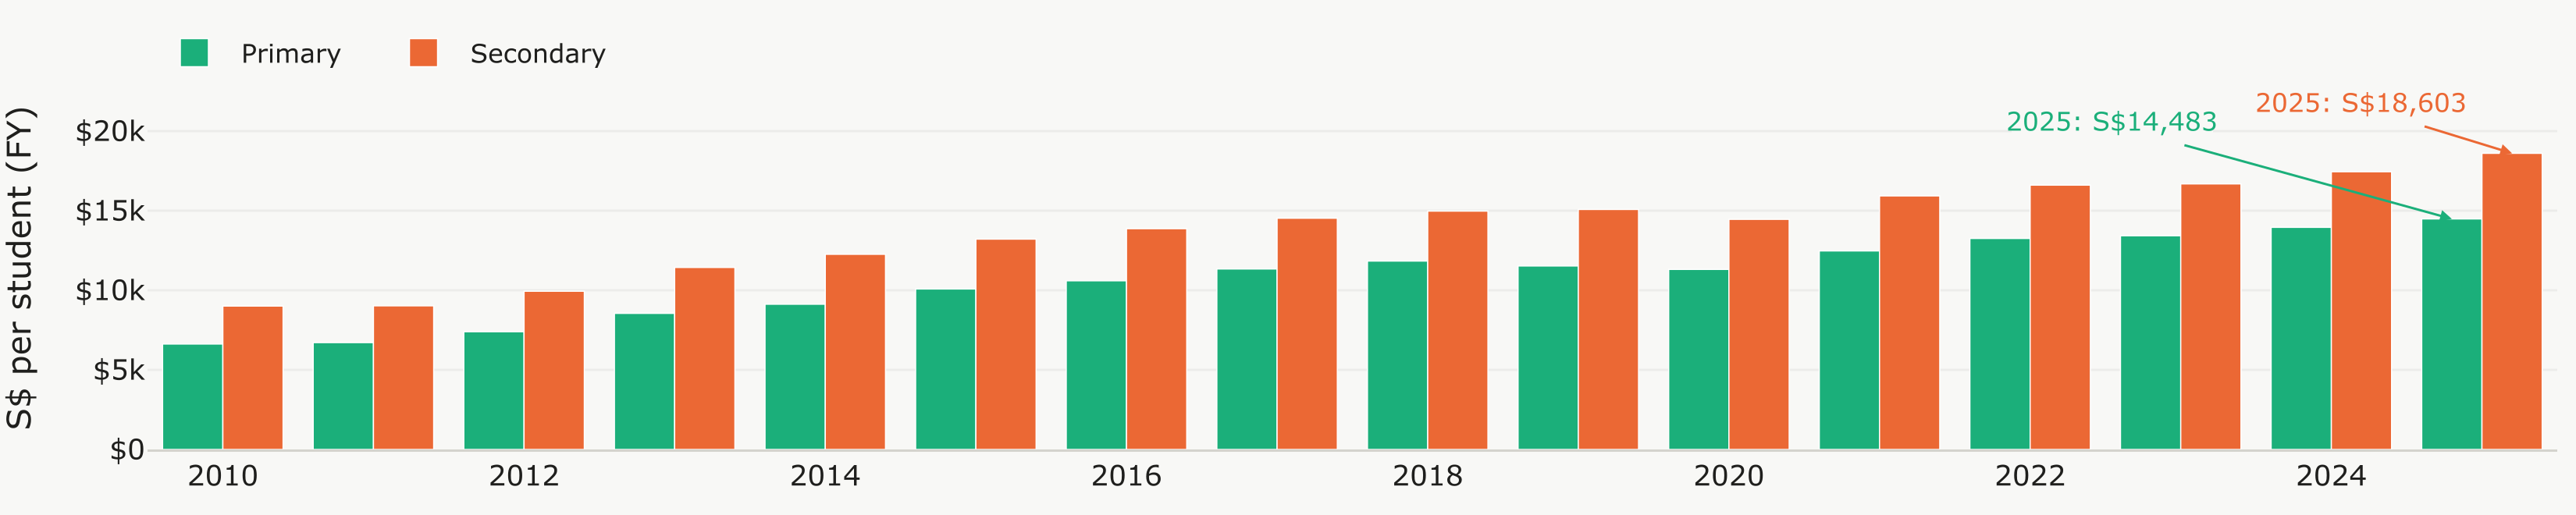

In [7]:
c3, c4 = st.columns(2)
with c3, card("Government spending per student"):
    d = df.dropna(subset=["Edu_Primary_per_Student"])
    fig = go.Figure()
    for c, n, col in [("Edu_Primary_per_Student", "Primary", AQUA), ("Edu_Secondary_per_Student", "Secondary", ORANGE)]:
        fig.add_trace(go.Bar(x=d.Year, y=d[c], name=n, marker_color=col, hovertemplate="FY%{x} " + n + ": S$%{y:,.0f}<extra></extra>"))
    fig.update_layout(barmode="group", bargap=0.2)
    fig.update_yaxes(title_text="S$ per student (FY)", tickprefix="$")
    show(style(fig, 300, hover="closest"))
    note("Primary: " + trend(df, "Edu_Primary_per_Student", "${:,.0f}"), "financial years", "click a bar to focus",
         src("Edu_Primary_per_Student"))



**Insight:** Public spending per pupil more than doubled in both primary and secondary education.

## 4. Education budget allocation

Source: SingStat M850011. FY2025 revised estimates.

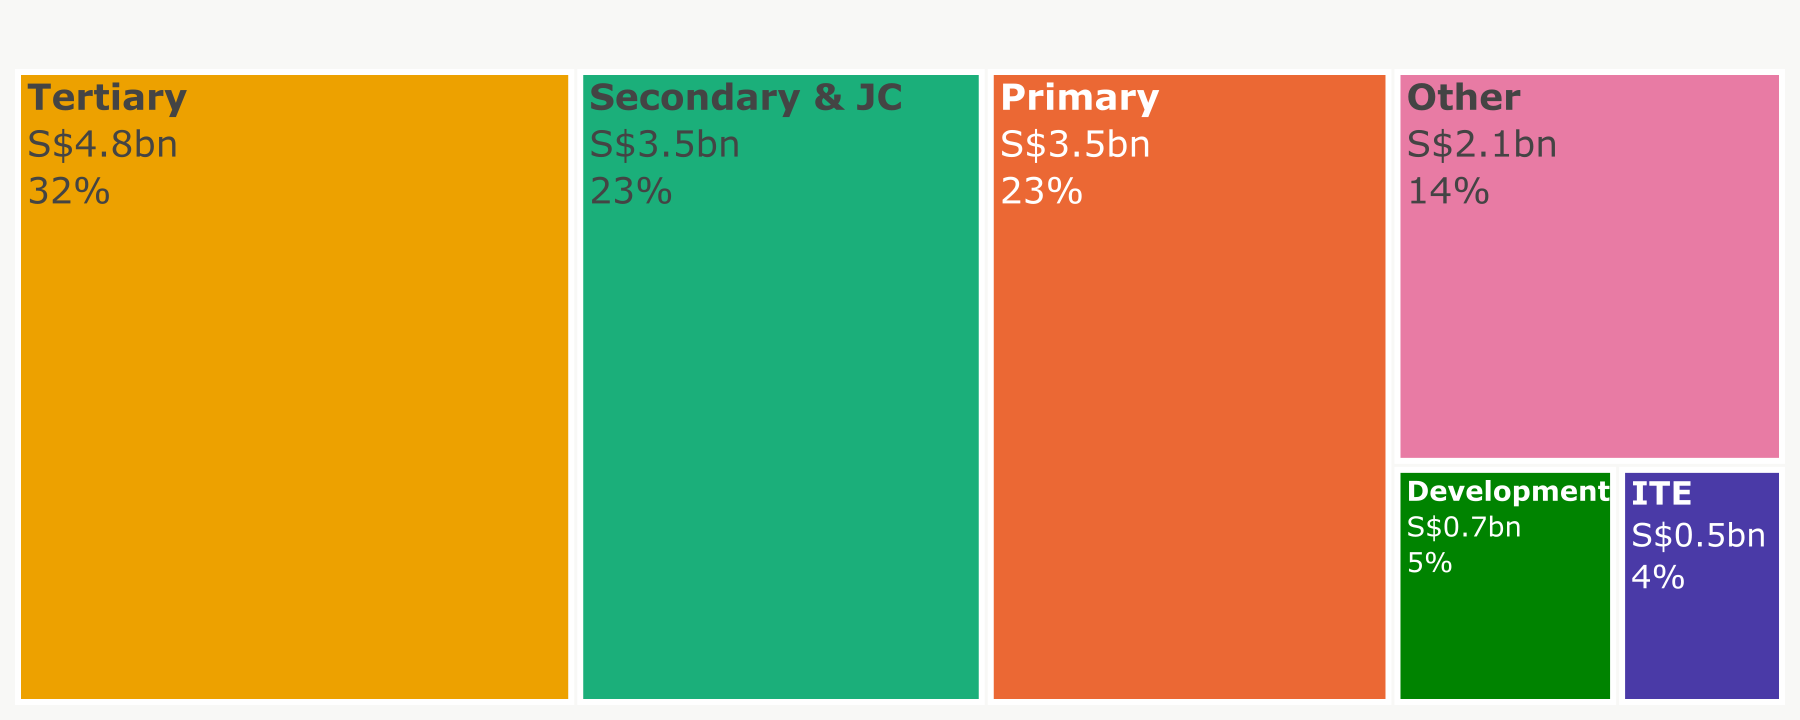

In [8]:
with c4, card("Where education funding goes"):
    OPS = {"Edu_Op_Primary": "Primary", "Edu_Op_Secondary_JC": "Secondary & JC", "Edu_Op_ITE": "ITE",
           "Edu_Op_Tertiary": "Tertiary", "Edu_Op_Other": "Other", "Edu_Development": "Development"}
    yrs = df.dropna(subset=list(OPS)).Year.astype(int).tolist()
    yr = st.select_slider("Year", yrs, value=yrs[-1], key="edu_tree", label_visibility="collapsed")
    v = df.set_index("Year").loc[yr, list(OPS)] / 1000
    fig = go.Figure(go.Treemap(labels=list(OPS.values()), parents=[""] * len(OPS), values=v.values,
                               marker=dict(colors=SERIES[:6], line=dict(color="white", width=2)),
                               texttemplate="<b>%{label}</b><br>S$%{value:.1f}bn<br>%{percentRoot:.0%}",
                               hovertemplate="%{label}: S$%{value:.2f}bn<extra></extra>"))
    show(style(fig, 280, legend=False, hover="closest").update_layout(margin=dict(l=0, r=0, t=0, b=0)))
    note(f"FY{yr} total S${v.sum():.1f}bn", src("Edu_Public_Total"))



**Insight:** Primary and secondary/JC received 46.1% of FY2025 education funding. Together with higher spending per pupil, this shows sustained public support for schooling within a wider education budget.

## 5. Education prices and TFR

Source: SingStat M213801 and M810091. Pearson r and two-sided p-values use 16 annual level observations from 2010 to 2025.


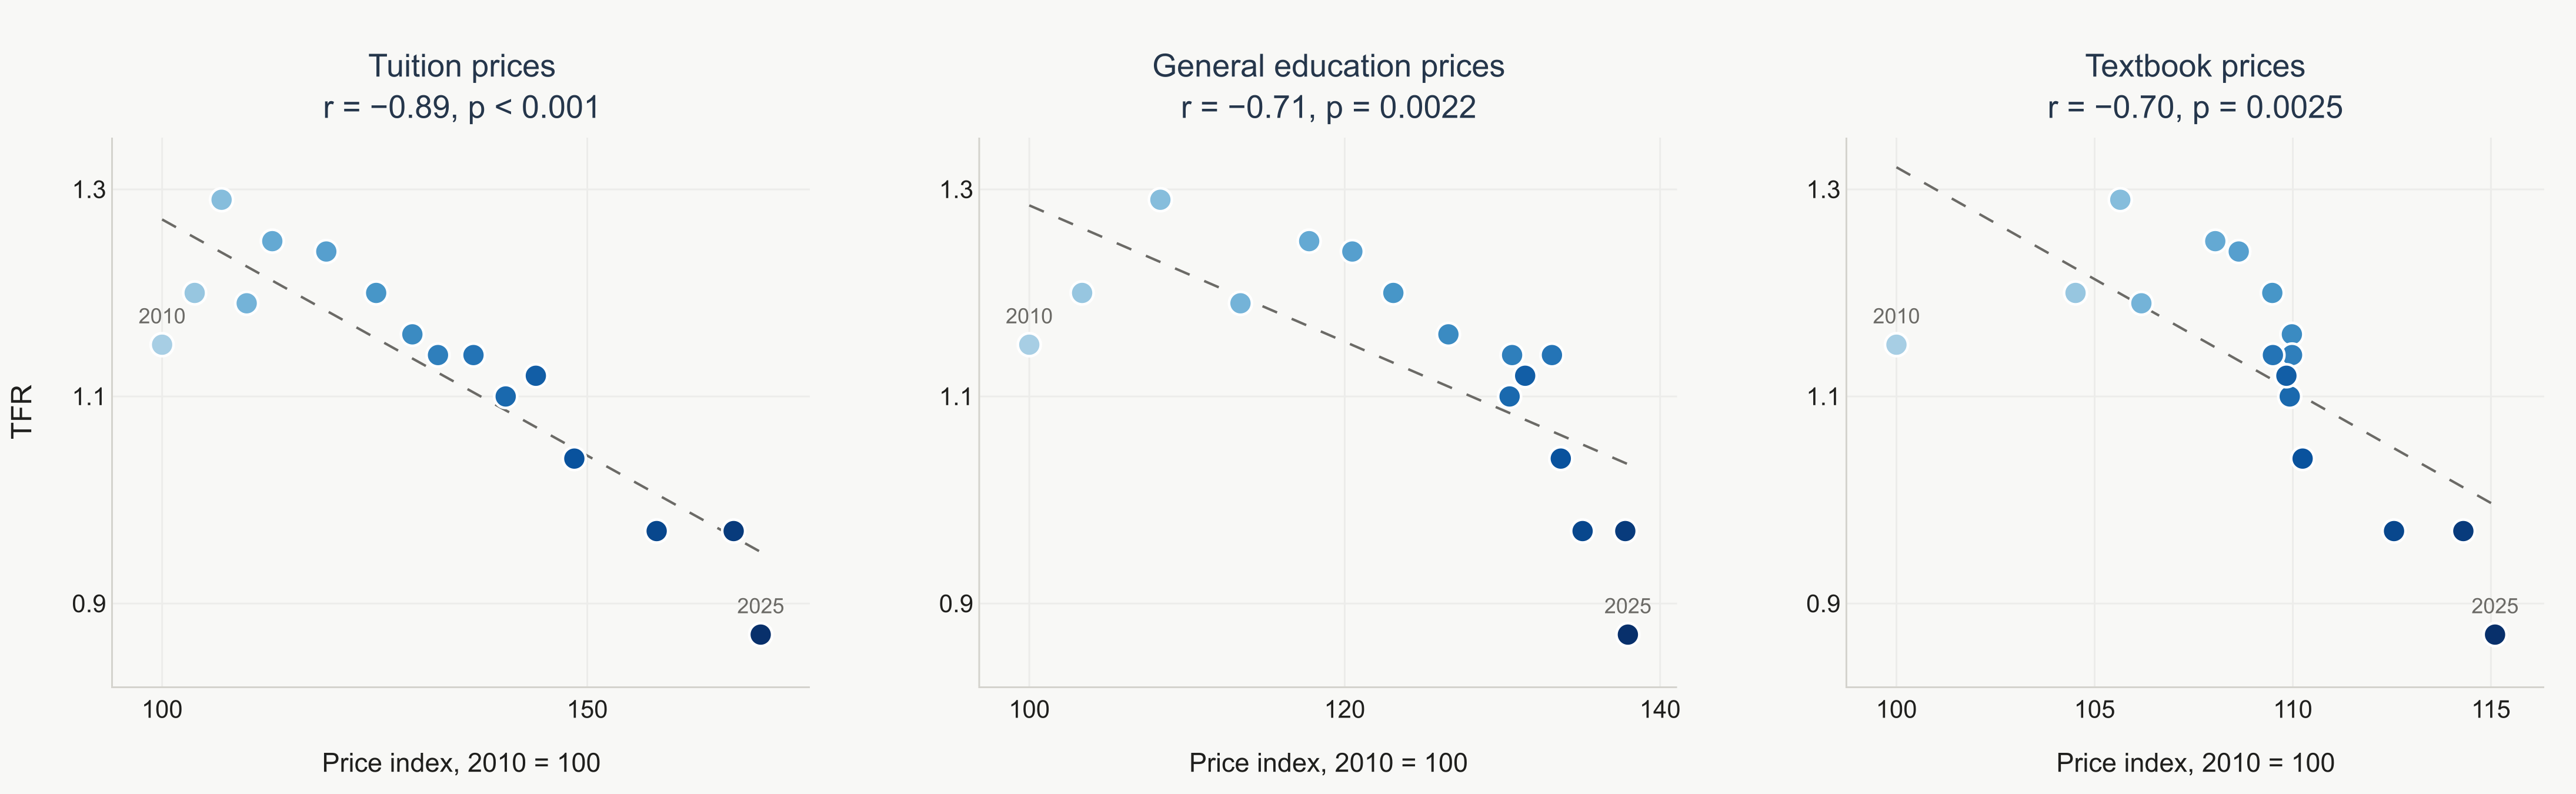

In [9]:
from pathlib import Path
import copy

import numpy as np
import pandas as pd
import plotly.graph_objects as go
import plotly.io as pio
from scipy.stats import pearsonr
from plotly.subplots import make_subplots

BASE = Path.cwd()
df = load_section('education')   # read from Education_Data.csv
df = df[df.Year.between(2010, 2025)]
reference = pio.read_json(BASE / 'figures/05_tfr.json')

factors = [
    ('Edu_CPI_Tuition', 'Tuition prices', 'Price index, 2010 = 100'),
    ('Edu_CPI_General', 'General education prices', 'Price index, 2010 = 100'),
    ('Edu_CPI_Textbooks', 'Textbook prices', 'Price index, 2010 = 100'),
]

statistics = {}
for column, title, unit in factors:
    pair = df[[column, 'TFR']].dropna()
    result = pearsonr(pair[column], pair.TFR, alternative='two-sided')
    statistics[column] = {'r': float(result.statistic), 'p': float(result.pvalue), 'n': len(pair)}

titles = []
for column, title, unit in factors:
    stats = statistics[column]
    r_text = f"{stats['r']:.2f}".replace('-', '−')
    p_text = 'p < 0.001' if stats['p'] < 0.001 else f"p = {stats['p']:.4f}"
    titles.append(f'{title}<br>r = {r_text}, {p_text}')

fig = make_subplots(
    rows=1, cols=3, shared_yaxes=True,
    horizontal_spacing=0.07,
    subplot_titles=titles,
)
chart_data = {}
for i, (column, title, unit) in enumerate(factors):
    row, col = divmod(i, 3)
    row, col = row + 1, col + 1
    d = df[['Year', column, 'TFR']].dropna()
    years = d.Year.to_numpy()
    x = d[column].to_numpy()
    y = d.TFR.to_numpy()
    slope, intercept = np.polyfit(x, y, 1)
    fitted_x = np.linspace(x.min(), x.max(), 30)

    # Reuse the original scatter's trace styling and year colour mapping.
    fitted = go.Scatter(copy.deepcopy(reference.data[0].to_plotly_json()))
    fitted.update(x=fitted_x, y=intercept + slope * fitted_x)
    points = go.Scatter(copy.deepcopy(reference.data[1].to_plotly_json()))
    points.update(
        x=x, y=y, customdata=years,
        text=[str(year) if year in {years.min(), years.max()} else '' for year in years],
        hovertemplate='<b>%{customdata}</b><br>' + title + ': %{x:,.2f}<br>TFR: %{y:,.3f}<extra></extra>',
    )
    # A larger label font keeps the original endpoint years legible in the comparison.
    points.textfont.size = 12
    fig.add_trace(fitted, row=row, col=col)
    fig.add_trace(points, row=row, col=col)
    fig.update_xaxes(
        title_text=unit, title_font_size=15, tickfont_size=14,
        showgrid=True, gridcolor='#ececea', linecolor='#d4d3cd', zeroline=False,
        nticks=4, row=row, col=col,
    )
    fig.update_yaxes(
        range=[0.82, 1.35], tickvals=[0.9, 1.1, 1.3], tickformat='.1f',
        title_text='TFR' if col == 1 else None,
        title_font_size=16, tickfont_size=14, showticklabels=True,
        gridcolor='#ececea', linecolor='#d4d3cd', zeroline=False,
        row=row, col=col,
    )
    chart_data[column] = {'years': years.tolist(), 'x': x.tolist(), 'tfr': y.tolist(), 'pearson_r': statistics[column]['r'], 'p_value': statistics[column]['p'], 'n': statistics[column]['n']}

fig.update_layout(
    width=1460, height=450, template='plotly_white', showlegend=False,
    margin=dict(l=64, r=18, t=78, b=50),
    font=dict(family='Arial', size=15, color='#1f1f1d'),
    paper_bgcolor='#F8F8F6', plot_bgcolor='#F8F8F6', hovermode='closest',
)
fig.update_annotations(font=dict(family='Arial', size=18, color='#25364B'))
fig.write_json(BASE / 'figures/05_education_factors.json')

figures["05_education_factors"] = fig
display(Image(filename=str(BASE / "figures/05_education_factors.png"), width=1200))


**Insight:** Tuition: r = −0.89, p < 0.001. General education: r = −0.71, p = 0.0022. Textbooks: r = −0.70, p = 0.0025.
